# BD532 Lab 2.1 (Colab): ทำนายโรคใบข้าวโพดด้วย transfer learning และ noisy input

โน้ตบุ๊กนี้คือ **ฝั่ง training** ของ Lab 2.1 ส่วน **ฝั่ง serving** (FastAPI) ทำใน GitHub Codespaces ตามคู่มือ `BD532-Lab-Week2-CV.md`

> ⏱️ **ลำดับการทำวันนี้:** เปิดโน้ตบุ๊ก **Lab 2.2 (`BD532_Lab2_2_PPE_Colab.ipynb`) ก่อน** แล้วรันส่วน 0–1 เพื่อสั่งเทรน YOLO ไว้เบื้องหลัง จากนั้นจึงเปิดโน้ตบุ๊กนี้ในแท็บใหม่ (สองโน้ตบุ๊กใช้ runtime แยกกัน)

| ส่วน | เวลา | เนื้อหา | ผลลัพธ์ |
|---|---|---|---|
| 0 | 13:10 | เปิด GPU, ติดตั้ง Ultralytics, เชื่อม Google Drive | พร้อมเทรน |
| 1–4 | 13:15 | ข้อมูลใบข้าวโพด, ฟังก์ชัน noise, ชุดเทรน noisy, โมเดล pretrained | ชุดข้อมูลสะอาดและ noisy |
| 5–6 | 13:20 | เทรนโมเดล A (สะอาด) และ B (สะอาด + noisy), robustness curve | ตารางเทียบความทนทาน |
| 7 | 13:30 | export | `bd532_leaf_artifacts.zip` |

> 💡 นักศึกษามีพื้นฐาน deep learning แล้ว โน้ตบุ๊กนี้ทบทวนเฉพาะสิ่งที่ต้องใช้ในการ deploy: **ไฟล์โมเดล, ขนาดภาพ (`imgsz`), ชื่อคลาส, เวอร์ชัน library, ฟังก์ชันที่ใช้เตรียมข้อมูล และคำตอบตัวอย่างไว้ตรวจ API**

**ทำไมต้องเก็บสิ่งเหล่านี้ให้ API:** API ต้องเตรียมภาพแบบเดียวกับตอนเทรนทุกประการ ถ้า `imgsz` หรือเวอร์ชัน library ต่างกัน คำตอบจะเพี้ยนโดยไม่มี error (training/serving skew) เราจึง export ไฟล์ `metadata.json` และ "คำตอบที่ถูกต้อง" ของรูปตัวอย่างไปด้วย เพื่อใช้ตรวจ API ใน Codespaces

## ส่วน 0: เตรียมเครื่อง (5 นาที)

1. เมนู **Runtime → Change runtime type → Hardware accelerator: T4 GPU** → **Save**
2. รันเซลล์ด้านล่างทีละเซลล์ (`Shift + Enter`)

In [2]:
!nvidia-smi -L    # ต้องเห็น "GPU 0: Tesla T4" ถ้าขึ้น command not found แปลว่ายังไม่ได้เปิด GPU

GPU 0: Tesla T4 (UUID: GPU-fb5135f4-caee-f111-8c5e-2b233e3e3575)


In [3]:
# ตรึงเวอร์ชันให้ตรงกับ Codespaces (requirements.txt) — สำคัญมากสำหรับการ deploy

%pip install -q ultralytics==8.4.202 # set library เวลา deploy ต้องใช้เวอชั่นเดียวกัน ultralytics==8.4.202 คือเวอชั่นของ YOLO
import ultralytics
ultralytics.checks()

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [5]:
# เก็บผลการเทรนไว้ใน Google Drive: ถ้า session หลุด ไฟล์โมเดลยังอยู่
from google.colab import drive
drive.mount("/content/drive")

import os
BASE = "/content/drive/MyDrive/bd532"      # โฟลเดอร์งานใน Drive เซฟพวกโมเดลสิ่งที่เกี่ยวกับการ deploy
DATASETS = "/content/datasets"             # ข้อมูลเก็บในเครื่อง Colab (เร็วกว่า Drive) จะหายไปถ้าปิดเครื่อง
os.makedirs(BASE, exist_ok=True)
print("ผลการเทรนจะอยู่ที่", BASE)

Mounted at /content/drive
ผลการเทรนจะอยู่ที่ /content/drive/MyDrive/bd532


> ✅ **Checkpoint 0**: เห็น `Tesla T4`, `ultralytics.checks()` แสดง `Ultralytics 8.4.202 ... CUDA:0 (Tesla T4 ...)` และ Drive ถูก mount แล้ว

> 🆘 **ถ้า Colab ไม่ให้ GPU กับโน้ตบุ๊กนี้** (เช่น ขึ้นข้อความว่าเชื่อมต่อ GPU ไม่ได้ เพราะบัญชีฟรีใช้ GPU กับโน้ตบุ๊ก Lab 2.2 อยู่แล้ว) ให้เลือก **Runtime → Change runtime type → CPU** แล้วทำต่อได้ ในส่วน 5 ตั้ง `CLS_EPOCHS = 3` การเทรนสองโมเดลบน CPU ใช้เวลาประมาณ 15 นาที (ระหว่างรอให้อ่านคู่มือ Lab 2.1-B ล่วงหน้า)

## โจทย์ Lab 2.1: ทำนายโรคใบข้าวโพดด้วย transfer learning และการเทรนด้วย noisy input

**โจทย์:** เกษตรกรถ่ายรูปใบข้าวโพดด้วยมือถือ แล้วส่งให้ API บอกว่าเป็นโรคอะไร

| คลาสที่ API ตอบ | โรค (ภาษาไทย) | ลักษณะที่เห็น |
|---|---|---|
| `gray_leaf_spot` | โรคใบจุดสีเทา (Cercospora) | แผลสี่เหลี่ยมยาวสีเทาตามแนวเส้นใบ |
| `common_rust` | โรคราสนิม | ตุ่มนูนสีน้ำตาลแดงกระจายทั่วใบ |
| `northern_leaf_blight` | โรคใบไหม้แผลใหญ่ | แผลรูปกระสวยยาวสีเทาอมเขียว |
| `healthy` | ใบปกติ | — |

**ข้อมูล:** ภาพใบข้าวโพด 3,852 ภาพจาก [PlantVillage](https://github.com/spMohanty/PlantVillage-Dataset) (สัญญาอนุญาต CC BY-SA 3.0) ถ่ายใน **สภาพควบคุม** แสงดี พื้นหลังเรียบ

**ปัญหาเมื่อนำไปใช้จริง:** ภาพจากมือถือในแปลงมี noise จากเซนเซอร์ เบลอเพราะมือสั่น แสงน้อยหรือย้อนแสง และถูกบีบอัดเมื่อส่งผ่านแอปแชต โมเดลที่เห็นแต่ภาพสะอาดตอนเทรนอาจทายผิดเมื่อเจอภาพแบบนี้ เราจึงจะ

1. เขียนฟังก์ชัน `add_noise()` จำลองภาพจากมือถือ โดยปรับความแรงได้ (`strength` 0–1)
2. เทรน **โมเดล A** ด้วยภาพสะอาด และ **โมเดล B** ด้วยภาพสะอาด + ภาพที่ใส่ noise
3. วัดความแม่นยำของทั้งสองโมเดลเมื่อ noise แรงขึ้นเรื่อย ๆ (robustness curve)
4. Export โมเดล B ไปทำ API

## ส่วน 1: ดาวน์โหลดเฉพาะภาพข้าวโพด และแบ่ง train/val

In [6]:
import glob, os, random, re, shutil, subprocess

PV = f"{DATASETS}/PlantVillage-Dataset"
LEAF = f"{DATASETS}/corn"                       # ชุดข้อมูลสะอาด: train/<class>, val/<class>
CLASSES = {                                     # ชื่อโฟลเดอร์เดิม → ชื่อคลาสที่ API จะตอบ
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": "gray_leaf_spot",
    "Corn_(maize)___Common_rust_": "common_rust",
    "Corn_(maize)___Northern_Leaf_Blight": "northern_leaf_blight",
    "Corn_(maize)___healthy": "healthy",
}

# repo ทั้งหมดมี 54,000 ภาพ ใช้ sparse checkout ดึงเฉพาะโฟลเดอร์ข้าวโพด (~58 MB, ไม่กี่วินาที) โหลดภาพจาก github
if not os.path.isdir(PV):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                    "https://github.com/spMohanty/PlantVillage-Dataset", PV], check=True)
    subprocess.run(["git", "-C", PV, "sparse-checkout", "set", "--no-cone", "raw/color/Corn_(maize)*"], check=True)

# แบ่ง 80/20 ตาม "รหัสภาพต้นฉบับ" (เช่น 'R.S_HL 8315 copy 2' → 'R.S_HL 8315')
# ภาพที่มีรหัสเดียวกันอยู่ฝั่งเดียวกันเสมอ ป้องกันภาพชุดเดียวกันรั่วไปอยู่ทั้ง train และ val
def group_of(path):
    return re.sub(r"( copy( \d+)?)?\.\w+$", "", os.path.basename(path).split("___")[-1])

rnd = random.Random(42)
shutil.rmtree(LEAF, ignore_errors=True)
for src, name in CLASSES.items():
    files = sorted(glob.glob(f"{PV}/raw/color/{src}/*"))
    groups = sorted({group_of(f) for f in files})
    rnd.shuffle(groups)
    val_groups = set(groups[: int(len(groups) * 0.2)])
    for f in files:
        split = "val" if group_of(f) in val_groups else "train"
        os.makedirs(f"{LEAF}/{split}/{name}", exist_ok=True)
        shutil.copy(f, f"{LEAF}/{split}/{name}/{os.path.basename(f).replace(' ', '_')}")
    n_tr = len(os.listdir(f"{LEAF}/train/{name}")); n_va = len(os.listdir(f"{LEAF}/val/{name}"))
    print(f"{name:<22} train {n_tr:>5}   val {n_va:>4}")

gray_leaf_spot         train   409   val  104
common_rust            train   954   val  238
northern_leaf_blight   train   789   val  196
healthy                train   920   val  242


มีเรื่อง class imbalance แค่นิดหน่อย
  - gray_leaf_spot จะมีภาพน้อยกว่าคนอื่น
  - common_rust   common_rust    จะมากสุด

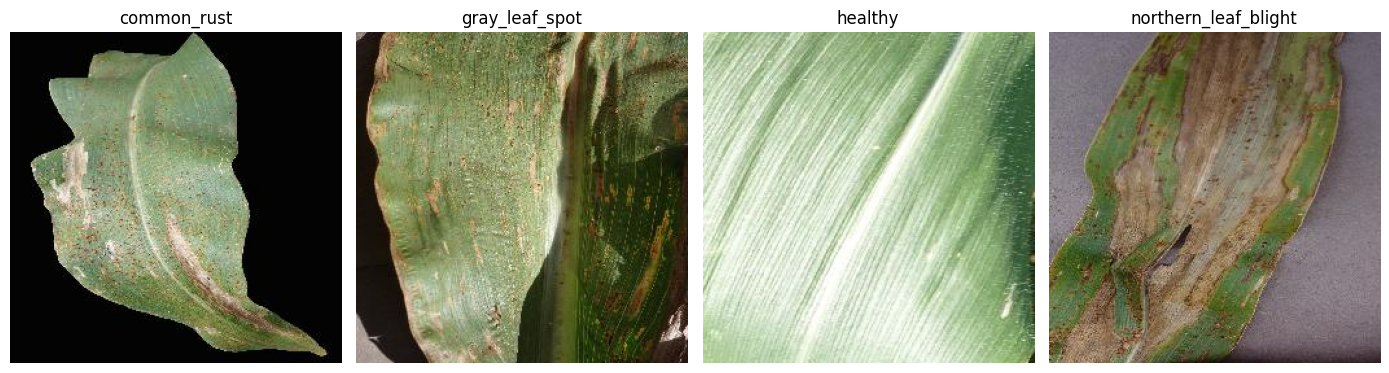

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(os.listdir(f"{LEAF}/train"))
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, c in zip(axes, classes):
    f = sorted(glob.glob(f"{LEAF}/train/{c}/*"))[0]
    ax.imshow(Image.open(f)); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

**คำถามชวนคิด:** คลาส `gray_leaf_spot` มีภาพน้อยกว่าคลาสอื่นประมาณครึ่งหนึ่ง จะส่งผลกับโมเดลอย่างไร และ metric ใดควรดูนอกจาก accuracy

## ส่วน 2: ฟังก์ชันจำลองภาพจากมือถือ (`leaf_noise.py`)

เขียนเป็นไฟล์ `.py` แยก เพราะจะ **ใช้ฟังก์ชันเดียวกันทุกที่**: สร้างภาพเทรน, สร้างภาพทดสอบ, และใน Codespaces ใช้ทดสอบ API (ถ้าแต่ละที่เขียน noise เองคนละแบบ ผลการทดสอบจะเทียบกันไม่ได้)

In [8]:
%%writefile leaf_noise.py
# จำลองภาพใบไม้ที่ถ่ายด้วยมือถือในแปลงจริง ใช้ทั้งตอนเทรน ตอนวัดผล และตอนทดสอบ API
import io

import numpy as np
from PIL import Image, ImageEnhance, ImageFilter


def add_noise(img: Image.Image, strength: float, rng: np.random.Generator) -> Image.Image:
    # strength 0 = ภาพเดิม, 1 = ภาพแย่มาก · rng = np.random.default_rng(seed) เพื่อให้ทำซ้ำได้
    img = img.convert("RGB")
    if strength <= 0:
        return img
    img = ImageEnhance.Brightness(img).enhance(max(0.1, 1 + strength * rng.uniform(-0.55, 0.45)))  # มืด / จ้า
    img = ImageEnhance.Contrast(img).enhance(max(0.1, 1 - strength * rng.uniform(0.0, 0.5)))      # หมอก / ย้อนแสง
    img = img.filter(ImageFilter.GaussianBlur(strength * rng.uniform(0.5, 2.5)))          # โฟกัสพลาด / มือสั่น
    a = np.asarray(img, dtype=np.float32)
    a = a + rng.normal(0, strength * rng.uniform(10, 40), a.shape)                         # noise จากเซนเซอร์ ตรงนี้คือการเพิ่มพิกเซลมี strength หลายแบบ
    img = Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=max(5, int(90 - strength * rng.uniform(40, 75))))  # บีบอัดตอนส่งผ่านแชต
    buf.seek(0)
    return Image.open(buf).convert("RGB")

Writing leaf_noise.py


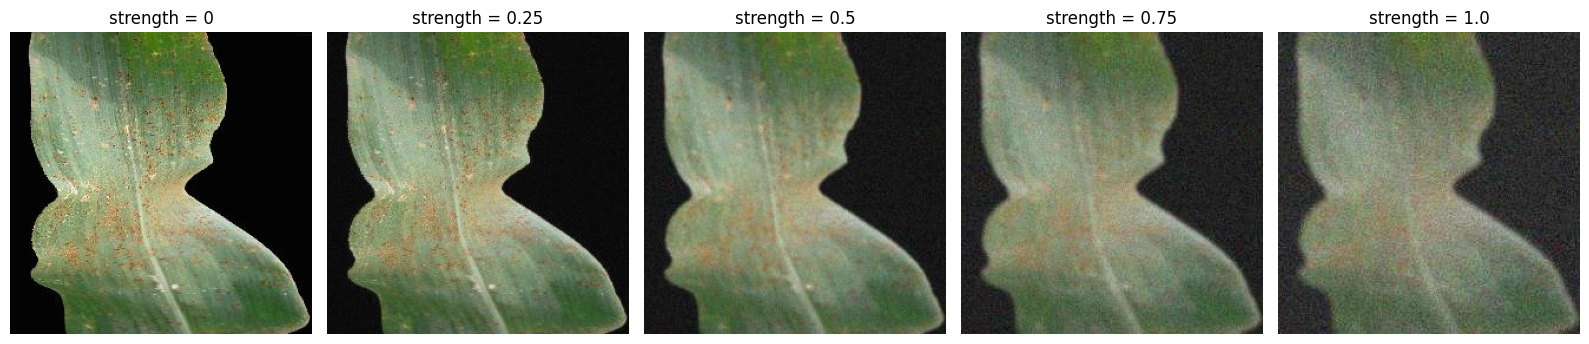

In [9]:
# แสดงภาพที่เพิ่ม noisy ถ้ามี strength สูงๆยิ่งมี noisy

import numpy as np
from leaf_noise import add_noise

f = sorted(glob.glob(f"{LEAF}/val/common_rust/*"))[0]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, s in zip(axes, [0, 0.25, 0.5, 0.75, 1.0]):
    ax.imshow(add_noise(Image.open(f), s, np.random.default_rng(7)))
    ax.set_title(f"strength = {s}"); ax.axis("off")
plt.tight_layout(); plt.show()

## ส่วน 3: สร้างชุดเทรนแบบ noisy

ชุดเทรนของโมเดล B = ภาพเดิมทุกภาพ + **สำเนาที่ใส่ noise 1 ภาพต่อ 1 ภาพเดิม** (สุ่ม `strength` ระหว่าง 0.3–1.0) ส่วน **val ยังเป็นภาพสะอาดชุดเดิม** เพื่อให้เทียบสองโมเดลได้ยุติธรรม

> ทำไมไม่ใช้ augmentation ในตัวของ Ultralytics: augmentation ในตัว (`auto_augment=randaugment`, `hsv_*`, `fliplr`, `erasing`) เปลี่ยนสีและรูปทรง แต่ **ไม่มี** sensor noise, ความเบลอ และ JPEG คุณภาพต่ำ ซึ่งเป็นปัญหาหลักของภาพจากมือถือ เราจึงสร้างภาพเพิ่มเอง (offline augmentation) ซึ่งตรวจดูภาพที่สร้างได้ด้วยตา

In [10]:
# ทำการเทรน noise โดยมีฟังชั่นที่เป็น add_noise
# สร้าง noise เพิ่ม

LEAF_NOISY = f"{DATASETS}/corn_noisy"
shutil.rmtree(LEAF_NOISY, ignore_errors=True)
shutil.copytree(f"{LEAF}/train", f"{LEAF_NOISY}/train")    # ภาพเดิม
shutil.copytree(f"{LEAF}/val", f"{LEAF_NOISY}/val")        # val สะอาด ชุดเดียวกับโมเดล A

TRAIN_NOISE = (0.3, 1.0)
rng = np.random.default_rng(0)
train_files = sorted(glob.glob(f"{LEAF}/train/*/*"))
for f in train_files:
    cls, stem = f.split("/")[-2], os.path.splitext(os.path.basename(f))[0]
    noisy = add_noise(Image.open(f), rng.uniform(*TRAIN_NOISE), rng)
    noisy.save(f"{LEAF_NOISY}/train/{cls}/{stem}_noisy.jpg", quality=95)

print("train สะอาด:", len(train_files), "ภาพ → train noisy:", len(glob.glob(f"{LEAF_NOISY}/train/*/*")), "ภาพ")

train สะอาด: 3072 ภาพ → train noisy: 6144 ภาพ


ได้ภาพสะอาดและได้ภาพที่มี noise มาเป็นประมาร 1 ต่อ 2

## ส่วน 4: โมเดล pretrained ตอบอะไร

`yolo26n-cls.pt` เรียนรู้จาก ImageNet 1,000 คลาส ซึ่ง **ไม่มีคลาสโรคพืช** ลองให้ทายภาพใบที่เป็นโรคราสนิม

In [11]:
# โหลด pretrained มาเพื่อดูว่ามันจะตอบอะไร

from ultralytics import YOLO

pre = YOLO("yolo26n-cls.pt")
r = pre.predict(f, verbose=False)[0] # ให้ predict f ผลออกมาเป็น class อะไรไม่รู้
for i in r.probs.top5:
    print(f"  {pre.names[i]:<20} {float(r.probs.data[i]):.3f}")

  ear                  0.369
  snail                0.270
  tailed_frog          0.086
  lacewing             0.047
  alligator_lizard     0.025


ผลของภาพสุดท้ายที่มัน predict ออกมา

In [12]:
print(f)

/content/datasets/corn/train/northern_leaf_blight/ffbc3745-0a6d-4145-8f92-781edc626d9f___RS_NLB_4260.JPG


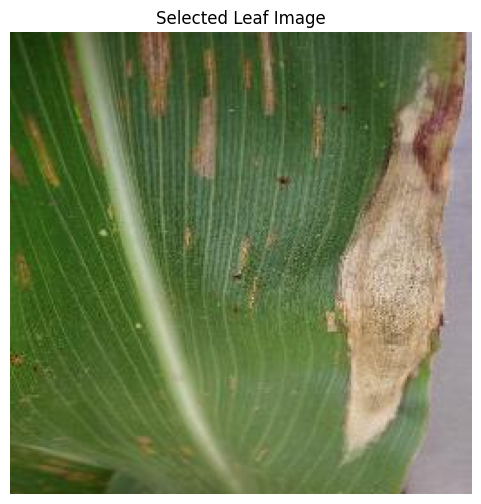

In [13]:
# ให้แสดงรูปออกมาว่าภาพสุดท้ายคืออะไร ผลออกมาไม่รู้ว่าเป็นโรคพืชอะไรเลยต้องเอาไปเทรน

import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(f)
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis('off')
plt.title("Selected Leaf Image")
plt.show()

โมเดลเดิมตอบได้แค่ชื่อใน ImageNet แต่ **backbone** ของมันสกัดลักษณะของภาพ (ขอบ ลาย สี จุด) ได้ดีแล้ว transfer learning จึงเก็บ backbone ไว้ เปลี่ยน **head** จาก 1,000 คลาสเป็น 4 คลาสโรคใบ แล้วเทรนต่อ

## ส่วน 5: เทรนโมเดล A (ภาพสะอาด) และโมเดล B (สะอาด + noisy)

ใช้ค่าเดียวกันทุกอย่าง ต่างกันแค่ชุดเทรน (โมเดล B ใช้เวลานานกว่าประมาณ 2 เท่าเพราะภาพมากกว่า 2 เท่า)

In [14]:
CLS_EPOCHS = 5
CLS_IMGSZ = 224          # API ต้องใช้ค่าเดียวกัน — จะถูกบันทึกลง metadata
RUN_A = f"{BASE}/runs/cls/leaf_clean"
RUN_B = f"{BASE}/runs/cls/leaf_noisy"

# เอา YOLO26nano ไปใช้กับ data ของเราที่เป็น leaf ทั้งหมด 5 epochs
YOLO("yolo26n-cls.pt").train(data=LEAF, epochs=CLS_EPOCHS, imgsz=CLS_IMGSZ, batch=64,
                             project=f"{BASE}/runs/cls", name="leaf_clean", exist_ok=True)

New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/corn, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.93

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79c82424ae70>
curves: []
curves_results: []
fitness: 0.9891025722026825
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.978205144405365, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9891025722026825}
save_dir: PosixPath('/content/drive/MyDrive/bd532/runs/cls/leaf_clean')
speed: {'preprocess': 0.11804238461548103, 'inference': 0.6306345064105338, 'loss': 9.193205123198987e-05, 'postprocess': 0.00015818846172339527}
top1: 0.978205144405365
top5: 1.0

ข้อมูลที่เทรนของภาพที่สะอาดได้
  - top1: 0.97 เก่งมาก
  - top5: 1.0

In [15]:
# Train leaf ที่เป็น noisy มีเยอะกว่าอันแรก 2 เท่าได้

YOLO("yolo26n-cls.pt").train(data=LEAF_NOISY, epochs=CLS_EPOCHS, imgsz=CLS_IMGSZ, batch=64,
                             project=f"{BASE}/runs/cls", name="leaf_noisy", exist_ok=True)

New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/corn_noisy, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentu

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79c845cfb5c0>
curves: []
curves_results: []
fitness: 0.985897421836853
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.971794843673706, 'metrics/accuracy_top5': 1.0, 'fitness': 0.985897421836853}
save_dir: PosixPath('/content/drive/MyDrive/bd532/runs/cls/leaf_noisy')
speed: {'preprocess': 0.16338989615408722, 'inference': 0.7291916102561713, 'loss': 0.00014429743606715652, 'postprocess': 0.0002492525640881911}
top1: 0.971794843673706
top5: 1.0

ได้ accurancy ไม่ต่างกันกับผลของภาพคลีนๆ

A: clean


,epoch,train/loss,val/loss,metrics/accuracy_top1
2,3,0.11673,0.25761,0.89615
3,4,0.09685,0.10330,0.96667
4,5,0.07968,0.06250,0.97821


B: clean+noisy


,epoch,train/loss,val/loss,metrics/accuracy_top1
2,3,0.13595,0.09499,0.96538
3,4,0.12778,0.08329,0.97179
4,5,0.08293,0.08812,0.96667


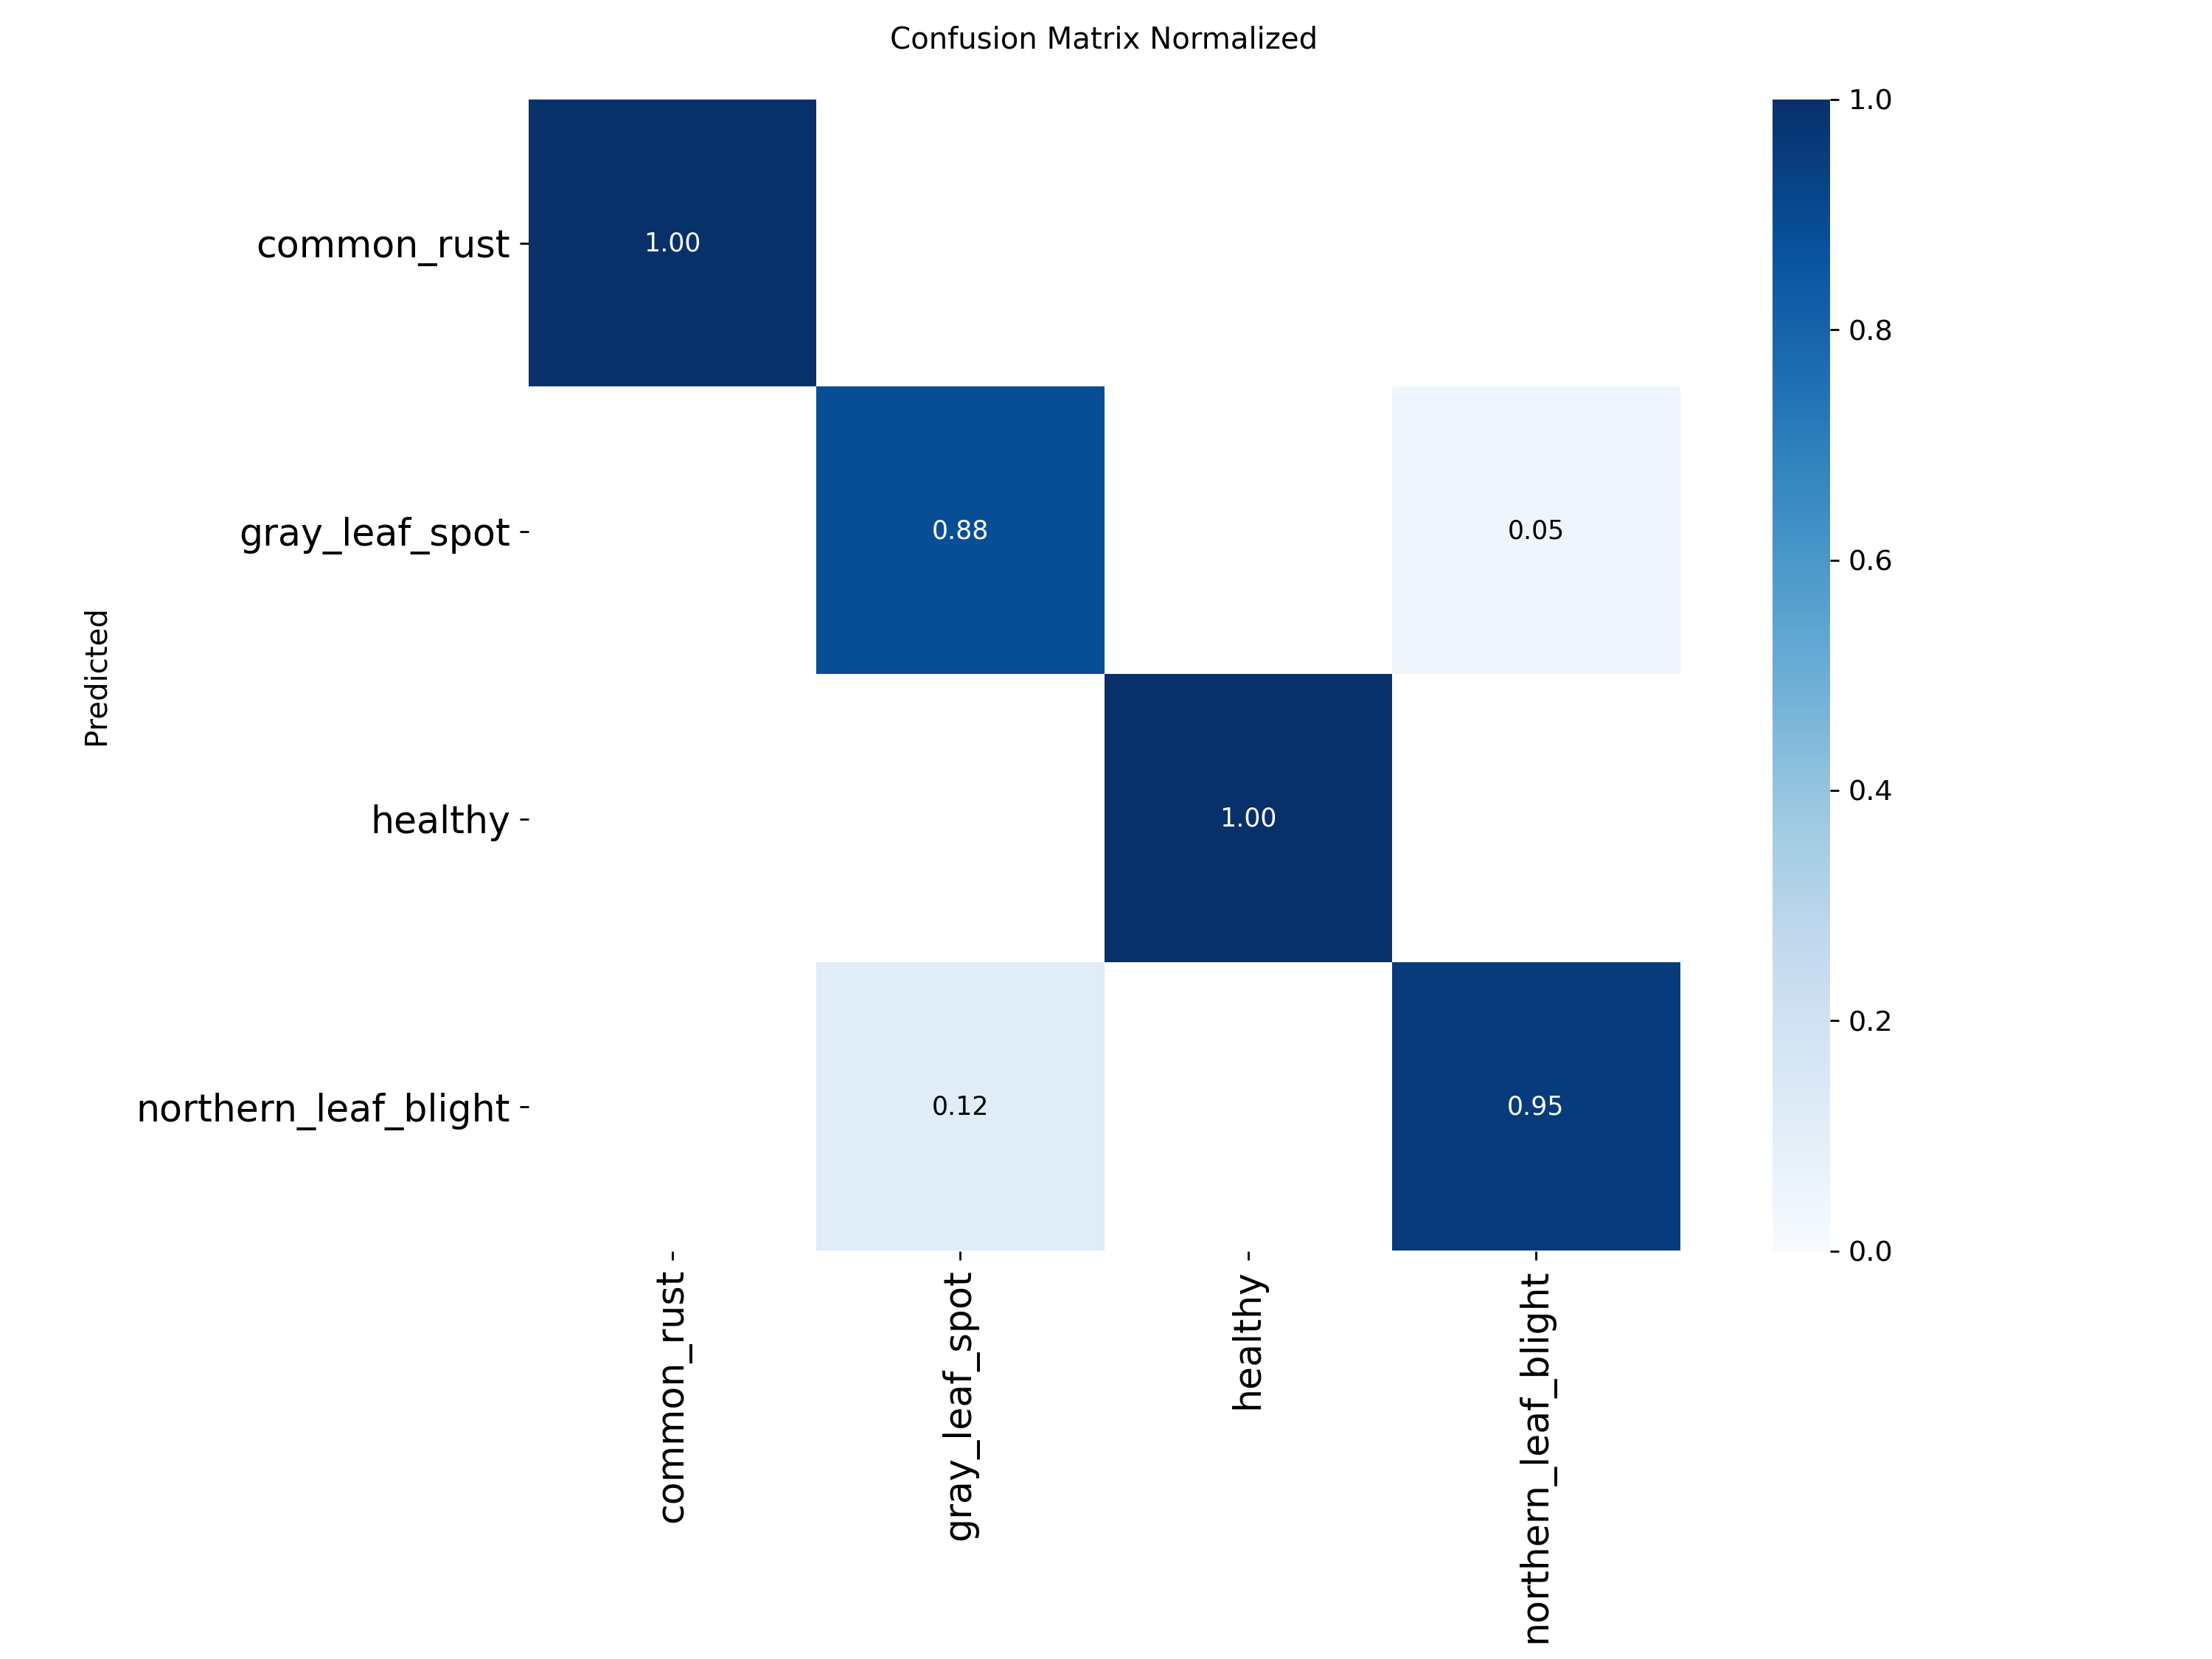

In [16]:
# ดูผลที่ได้ 2 ภาพ

import pandas as pd
from IPython.display import Image as Show, display

for name, run in [("A: clean", RUN_A), ("B: clean+noisy", RUN_B)]: # A = ภาพคลีน B = ผลจากการรันภาพที่มี noise
    df = pd.read_csv(f"{run}/results.csv"); df.columns = df.columns.str.strip()
    print(name); display(df[["epoch", "train/loss", "val/loss", "metrics/accuracy_top1"]].tail(3))
display(Show(f"{RUN_B}/confusion_matrix_normalized.png", width=480))

บนภาพ val ที่ **สะอาด** สองโมเดลได้ accuracy ใกล้กัน (ต่างกันไม่กี่จุด) ถ้าดูแค่ตัวเลขนี้อาจสรุปว่า "เทรนด้วย noise ก็ได้ผลพอ ๆ กัน" ซึ่งยังสรุปไม่ได้ เพราะยังไม่ได้ทดสอบกับภาพแบบที่ผู้ใช้จะส่งมาจริง

**คำถามชวนคิด:** การเปรียบเทียบนี้ยุติธรรมหรือไม่ ในเมื่อโมเดล B เห็นภาพมากกว่า 2 เท่าต่อ epoch (จำนวนรอบการปรับน้ำหนักมากกว่า 2 เท่า) ถ้าจะพิสูจน์ว่าความต่างมาจาก noise จริง ควรออกแบบการทดลองอย่างไร

<details><summary>เฉลย</summary>

ยังไม่ยุติธรรมทั้งหมด ความต่างบนภาพสะอาดบางส่วนอาจมาจากการเทรนนานกว่า วิธีควบคุม: ให้โมเดล A เทรน 2 เท่าของ epoch (`epochs=10`) หรือให้โมเดล B แทนที่ภาพเดิมด้วยภาพ noisy ครึ่งหนึ่งโดยคงจำนวนภาพเท่าเดิม แล้วเทียบใหม่ หลักการคือ **เปลี่ยนทีละปัจจัย**
</details>

## ส่วน 6: Robustness curve: ความแม่นยำเมื่อ noise แรงขึ้น

นำภาพ val ทุกภาพมาใส่ noise ที่ `strength` 0, 0.25, 0.5, 0.75, 1.0 (ใช้ seed เดียวกัน สองโมเดลจึงเจอภาพชุดเดียวกันทุกระดับ)

ถ้า 2 โมเดลใช้ strenght ตามข้างบน ผลที่ได้จะเป็นไง

,noise strength,A: clean,B: clean+noisy
0,0.00,0.9782,0.9718
1,0.25,0.9756,0.9744
2,0.50,0.9295,0.9679
3,0.75,0.7603,0.9603
4,1.00,0.6231,0.9321


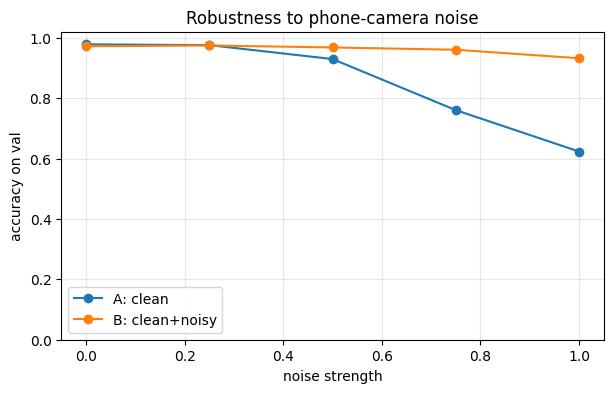

In [17]:
val_files = sorted(glob.glob(f"{LEAF}/val/*/*"))
val_labels = [p.split("/")[-2] for p in val_files]
models = {"A: clean": YOLO(f"{RUN_A}/weights/best.pt"), "B: clean+noisy": YOLO(f"{RUN_B}/weights/best.pt")}
LEVELS = [0, 0.25, 0.5, 0.75, 1.0]

def predict_labels(model, images, bs=64):
    out = []
    for i in range(0, len(images), bs):
        out += [r.names[r.probs.top1] for r in model.predict(images[i:i + bs], imgsz=CLS_IMGSZ, verbose=False)]
    return out

rows = []
for s in LEVELS:
    rng = np.random.default_rng(123)
    noisy_val = [add_noise(Image.open(p), s, rng) for p in val_files]
    row = {"noise strength": s}
    for name, m in models.items():
        pred = predict_labels(m, noisy_val)
        row[name] = round(float(np.mean([p == y for p, y in zip(pred, val_labels)])), 4)
    rows.append(row)

robust = pd.DataFrame(rows)
display(robust)
ax = robust.plot(x="noise strength", y=list(models), marker="o", figsize=(7, 4), ylim=(0, 1.02))
ax.set_ylabel("accuracy on val"); ax.set_title("Robustness to phone-camera noise"); ax.grid(alpha=.3)
plt.show()

ถ้าใช้ strenght เยอะๆ โมเดลที่เทรนคลีนกับ noise ยังเก่งอยู่
ถ้าเทรนกับคลีนอย่างเดียวใช้ strenght เยอะผล accu ต่ำลงมาก

**คำถามชวนคิด**

1. ที่ `strength = 0` สองโมเดลต่างกันเท่าไร และที่ `strength = 1.0` ต่างกันเท่าไร
2. เทรนด้วย noise ที่ `strength` 0.3–1.0 แล้วโมเดล B ทนต่อ noise ได้ดีขึ้น ถ้าผู้ใช้จริงส่งภาพที่แย่กว่า `strength = 1.0` หรือแย่คนละแบบ (เช่น ใบไม้ซ้อนกันหลายใบ มีพื้นดินเป็นพื้นหลัง) จะยังทนได้หรือไม่
3. ควรเลือกโมเดลไป deploy จากตัวเลขในคอลัมน์ใด

<details><summary>เฉลย</summary>

1. ภาพสะอาดต่างกันน้อยมาก แต่ภาพที่มี noise แรงจะต่างกันชัดเจน การเทรนด้วย noise แทบไม่เสียความแม่นยำบนภาพสะอาด แต่เพิ่มความทนทานมาก
2. ไม่รับประกัน การเทรนด้วย noise ช่วยเฉพาะ noise **แบบที่จำลองไว้** ส่วนพื้นหลังที่ต่างไป (PlantVillage พื้นหลังเรียบ) คือ **domain shift** ที่ noise ช่วยไม่ได้ ต้องเก็บภาพจริงจากแปลงมาเทรนและทดสอบเพิ่ม (เชื่อมกับ Chapter 11 การเก็บ feedback)
3. เลือกจาก **ระดับ noise ที่ใกล้กับภาพที่ผู้ใช้จะส่งมาจริง** ไม่ใช่จาก val สะอาดอย่างเดียว ตัวเลขทั้งตารางควรบันทึกไว้ใน metadata ของโมเดล
</details>

## ส่วน 7: Export โมเดล B และสิ่งที่ API ต้องใช้

เซลล์นี้สร้าง `bd532_leaf_artifacts.zip` ที่มี
- `models/leaf_best.pt` โมเดล B (ตัวที่ deploy) และ `models/leaf_clean.pt` โมเดล A (ไว้เทียบผ่าน API)
- `models/leaf_metadata.json` เวอร์ชันโมเดล, `imgsz`, ชื่อคลาส, accuracy, **ตาราง robustness ของทั้งสองโมเดล**, วิธีใส่ noise ตอนเทรน, เกณฑ์ `low_confidence`
- `leaf_noise.py` ฟังก์ชัน noise ตัวเดียวกับที่ใช้เทรน
- `samples/leaf/*.jpg` คลาสละ 2 ภาพ (สะอาด 1 + noisy 1) และ `samples/leaf_expected.json` คำตอบของโมเดลใน Colab
- `samples/leaf_val/*.jpg` ภาพ val สะอาดคลาสละ 5 ภาพ สำหรับทดสอบความทนทานของ API

มี include samples ไปด้วยเพื่อเวลาเอาไป predict ต่างๆมันจะหาตัวอย่างได้ง่าย

In [18]:
import datetime, json
import ultralytics

OUT = "export_leaf"
shutil.rmtree(OUT, ignore_errors=True)
os.makedirs(f"{OUT}/models", exist_ok=True)
os.makedirs(f"{OUT}/samples/leaf", exist_ok=True)
os.makedirs(f"{OUT}/samples/leaf_val", exist_ok=True)
shutil.copy(f"{RUN_B}/weights/best.pt", f"{OUT}/models/leaf_best.pt")     # โมเดล B → deploy
shutil.copy(f"{RUN_A}/weights/best.pt", f"{OUT}/models/leaf_clean.pt")    # โมเดล A → ไว้เทียบผ่าน API
shutil.copy("leaf_noise.py", f"{OUT}/leaf_noise.py")

model = YOLO(f"{OUT}/models/leaf_best.pt")
metrics = model.val(data=LEAF, imgsz=CLS_IMGSZ, verbose=False, plots=False)

# รูปตัวอย่าง: คลาสละ 1 ภาพสะอาด + 1 ภาพ noisy (strength 0.8) พร้อมคำตอบของโมเดลใน Colab
expected, rng = [], np.random.default_rng(2026)
for name in model.names.values():
    src = sorted(glob.glob(f"{LEAF}/val/{name}/*"))[0]
    for kind, img in [("clean", Image.open(src).convert("RGB")),
                      ("noisy", add_noise(Image.open(src), 0.8, rng))]:
        fname = f"{name}_{kind}.jpg"
        img.save(f"{OUT}/samples/leaf/{fname}", quality=95)
        r = model.predict(f"{OUT}/samples/leaf/{fname}", imgsz=CLS_IMGSZ, verbose=False)[0]
        expected.append({"file": fname, "true_label": name, "label": r.names[r.probs.top1],
                         "prob": round(float(r.probs.top1conf), 4)})
json.dump(expected, open(f"{OUT}/samples/leaf_expected.json", "w"), indent=2, ensure_ascii=False)

# ภาพ val สะอาดคลาสละ 5 ภาพ ไว้ทดสอบความทนทานของ API ใน Codespaces (robustness_api.py)
for name in model.names.values():
    for i, src in enumerate(sorted(glob.glob(f"{LEAF}/val/{name}/*"))[1:6]):
        shutil.copy(src, f"{OUT}/samples/leaf_val/{name}_{i}.jpg")

meta = {
    "model_version": "leaf-yolo26n-cls-noisy-v1",
    "task": "classify",
    "base_model": "yolo26n-cls.pt (ImageNet pretrained)",
    "dataset": "PlantVillage corn leaves, 4 classes (CC BY-SA 3.0)",
    "imgsz": CLS_IMGSZ,
    "names": model.names,
    "metrics": {"top1_clean_val": round(float(metrics.top1), 4)},
    "training_noise": {"function": "leaf_noise.add_noise", "strength_range": list(TRAIN_NOISE),
                       "noisy_copies_per_image": 1},
    "robustness": robust.to_dict(orient="records"),
    "low_confidence_below": 0.6,
    "ultralytics_version": ultralytics.__version__,
    "exported_at": datetime.datetime.now().isoformat(timespec="seconds"),
}
json.dump(meta, open(f"{OUT}/models/leaf_metadata.json", "w"), indent=2, ensure_ascii=False)
shutil.make_archive("bd532_leaf_artifacts", "zip", OUT)
print(json.dumps(meta["metrics"]), "| samples:", len(expected))
print("✅ สร้าง bd532_leaf_artifacts.zip แล้ว")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,531,148 parameters, 0 gradients, 3.2 GFLOPs
train: /content/datasets/corn/train... found 3072 images in 4/4 classes ✅ 
val: /content/datasets/corn/val... found 780 images in 4/4 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 819.9±323.4 MB/s, size: 14.7 KB)
val: Scanning /content/datasets/corn/val... 780 images, 0 corrupt: 100% ━━━━━━━━━━━━ 780/780 163.6Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 49/49 10.0it/s 4.9s
                   all      0.972          1
Speed: 0.1ms preprocess, 1.8ms inference, 0.0ms loss, 0.0ms postprocess per image
{"top1_clean_val": 0.9718} | samples: 8
✅ สร้าง bd532_leaf_artifacts.zip แล้ว


In [19]:
# dump ตัว label ออกไป ว่ามี metadata อะไรบ้าง

print(json.dumps(expected, indent=1, ensure_ascii=False)[:700])

[
 {
  "file": "common_rust_clean.jpg",
  "true_label": "common_rust",
  "label": "common_rust",
  "prob": 1.0
 },
 {
  "file": "common_rust_noisy.jpg",
  "true_label": "common_rust",
  "label": "common_rust",
  "prob": 1.0
 },
 {
  "file": "gray_leaf_spot_clean.jpg",
  "true_label": "gray_leaf_spot",
  "label": "gray_leaf_spot",
  "prob": 0.9635
 },
 {
  "file": "gray_leaf_spot_noisy.jpg",
  "true_label": "gray_leaf_spot",
  "label": "gray_leaf_spot",
  "prob": 0.7293
 },
 {
  "file": "healthy_clean.jpg",
  "true_label": "healthy",
  "label": "healthy",
  "prob": 1.0
 },
 {
  "file": "healthy_noisy.jpg",
  "true_label": "healthy",
  "label": "healthy",
  "prob": 1.0
 },
 {
  "file": "northe


In [20]:
from google.colab import files
files.download("bd532_leaf_artifacts.zip")

# โหลดไฟล์เก็บไว้ในเครื่องเพื่อเอาไปทำ Codespaces ต่อ...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

> ✅ **Checkpoint (ก่อนไป Lab 2.1-B ใน Codespaces)**
> - [ ] บันทึกตาราง robustness (accuracy ของโมเดล A และ B ที่ `strength` 0 และ 1.0)
> - [ ] อธิบายได้ว่าทำไมดู accuracy บน val สะอาดอย่างเดียวไม่พอ
> - [ ] มีไฟล์ `bd532_leaf_artifacts.zip` (~7 MB) บนเครื่อง
> - [ ] สลับไปแท็บโน้ตบุ๊ก Lab 2.2 รันเซลล์ `det_progress()` แล้วเห็นว่าเทรน PPE คืบหน้า
> - [ ] ดาวน์โหลดโน้ตบุ๊กนี้ที่รันแล้ว (**File → Download → Download .ipynb**) ไว้ commit ใน Codespaces

➡️ **ไปทำ Lab 2.1-B ในคู่มือ (Codespaces)**